This notebook was made to answer sub question 1 of this research project: is there a greater effect on the roads that changed from 50 to 30 km/h than on the roads without a change?

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shapely
import statsmodels.api as sm
import statsmodels.formula.api as smf
from pyproj import Transformer
from matplotlib.collections import LineCollection

# crashes with their road group, made in wegvakken.ipynb
accidents = pd.read_csv("data/crashes_amsterdam_classified.csv")
accidents = accidents.rename(columns={"VKL_NUMMER": "accident_id", "JAAR_VKL": "year", "AP3_CODE": "severity",
                                      "LOCATION_TYPE": "location_type", "ROAD_GROUP": "category"})
accidents["category"] = accidents["category"].replace({"50->30": "50 to 30", "always 30": "already 30"})

print("Accidents:", len(accidents))
print()
print(accidents["category"].value_counts())
print()
print(pd.crosstab(accidents["MATCH_METHOD"], accidents["location_type"]))

Accidents: 63291

category
other              19274
50 to 30           17912
already 30         15649
stayed 50           7030
mixed               1815
unknown              824
outside network      787
Name: count, dtype: int64

location_type      junction  segment
MATCH_METHOD                        
dertig_id                 0    29596
junction              20343        0
junction_location       288        0
none                      3      183
nwb_location              0    10998
speed_fallback            4      152
street_name               0     1724


In [2]:
with open("data/amsterdam_dertig.json") as f:
    features = json.load(f)["features"]

roads = pd.DataFrame([feat["properties"] for feat in features])
geoms = [shapely.geometry.shape(feat["geometry"]) for feat in features]


def road_category(old, new):
    if old == "GOW50" and new in ("GOW30", "ETW30"):
        return "50 to 30"
    if old == "GOW50" and new == "GOW50":
        return "stayed 50"
    if old in ("ETW30", "GOW30") and new in ("ETW30", "GOW30"):
        return "already 30"
    return "other"


roads["category"] = [road_category(o, n) for o, n in zip(roads["WEGTYPE_OUD"], roads["WEGTYPE_NIEUW"])]

# convert from lat/lon to RD coordinates (metres)
to_rd = Transformer.from_crs("EPSG:4326", "EPSG:28992", always_xy=True)


def convert(xy):
    x, y = to_rd.transform(xy[:, 0], xy[:, 1])
    return np.column_stack([x, y])


lines = shapely.transform(np.array(geoms), convert)
roads["length_km"] = shapely.length(lines) / 1000

print(pd.crosstab(roads["WEGTYPE_OUD"], roads["WEGTYPE_NIEUW"]))
print()
print(roads.groupby("category").agg(segments=("WVK_ID", "size"), length_km=("length_km", "sum")).round(0))

WEGTYPE_NIEUW         BUITEN N  ETW30  ETW60  GOW30  GOW50  GOW70  SW80PLUS
WEGTYPE_OUD                                                                
BUITEN NETWERK  1515         1     75      0     13      1      0         0
ETW30              3         0  17007      0     11      1      0         0
ETW60              0         0      1    110      0      2      0         0
GOW30              0         0      0      0    287      0      0         0
GOW50              0         0    814      0   3040   1800      0         0
GOW70              0         0      0      0      0      0    113         0
SW80PLUS           0         0      0      0      0     14      0       504

            segments  length_km
category                       
50 to 30        3854      360.0
already 30     17305     1372.0
other           2353      583.0
stayed 50       1800      278.0


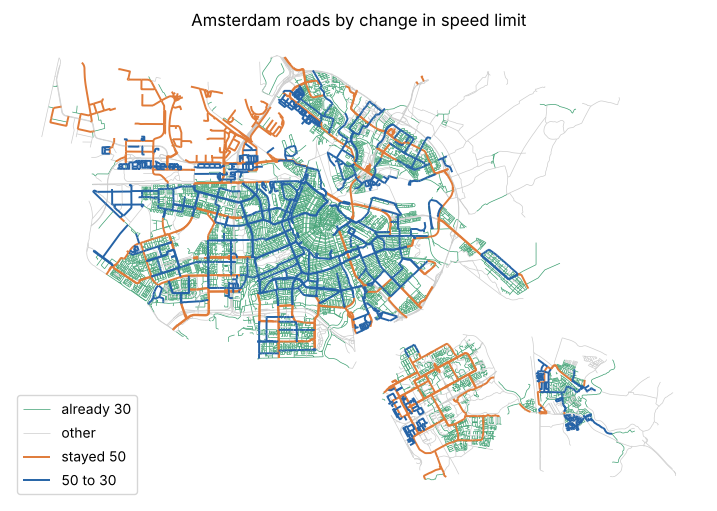

In [3]:
colors = {"50 to 30": "#2563A6", "stayed 50": "#E07B39", "already 30": "#3A9E6F", "other": "#CCCCCC"}
groups = ["50 to 30", "stayed 50", "already 30"]

fig, ax = plt.subplots(figsize=(9, 8))
for cat in ["already 30", "other", "stayed 50", "50 to 30"]:
    part = lines[(roads["category"] == cat).values]
    width = 1.4 if cat in ("50 to 30", "stayed 50") else 0.5
    ax.add_collection(LineCollection([np.asarray(g.coords) for g in shapely.get_parts(part)],
                                     colors=colors[cat], linewidths=width, label=cat))
ax.autoscale()
ax.set_aspect("equal")
ax.set_axis_off()
ax.legend(loc="lower left")
ax.set_title("Amsterdam roads by change in speed limit")
plt.savefig("RQ1_map_road_categories.png", dpi=200, bbox_inches="tight")
plt.show()

In [4]:
data = accidents[accidents["category"].isin(groups)].copy()
data["period"] = "before"
data.loc[data["year"] == 2023, "period"] = "transition"
data.loc[data["year"] >= 2024, "period"] = "after"
data["serious"] = data["severity"].isin(["LET", "DOD"])
data["fatal"] = data["severity"] == "DOD"

pd.crosstab(data["category"], data["period"])[["before", "transition", "after"]]

period,before,transition,after
category,,,
50 to 30,13047,1783,3082
already 30,11358,1560,2731
stayed 50,4861,773,1396


In [5]:
def count_per_year(d):
    return (d.groupby(["category", "year"])
             .agg(accidents=("accident_id", "size"), serious=("serious", "sum"), fatal=("fatal", "sum"))
             .reset_index())


per_year = count_per_year(data)
per_year["% serious"] = (100 * per_year["serious"] / per_year["accidents"]).round(1)
per_year.pivot(index="year", columns="category", values=["accidents", "serious", "fatal", "% serious"])

accidents                       serious                       \
category  50 to 30 already 30 stayed 50 50 to 30 already 30 stayed 50   
year                                                                    
2016        2199.0     2171.0     667.0    616.0      504.0     138.0   
2017        2211.0     1928.0     736.0    566.0      452.0     158.0   
2018        1989.0     1904.0     693.0    491.0      396.0     141.0   
2019        1857.0     1638.0     742.0    434.0      307.0     144.0   
2020        1429.0     1091.0     593.0    361.0      223.0     113.0   
2021        1587.0     1266.0     652.0    347.0      236.0     108.0   
2022        1775.0     1360.0     778.0    441.0      309.0     144.0   
2023        1783.0     1560.0     773.0    449.0      323.0     161.0   
2024        1616.0     1314.0     721.0    489.0      307.0     159.0   
2025        1466.0     1417.0     675.0    470.0      364.0     163.0   

            fatal                      % serious                       
category 50 to 30 already 30 stayed 50  50 to 30 already 30 stayed 50  
year                                                                   
2016          3.0        6.0       1.0      28.0       23.2      20.7  
2017          7.0        0.0       4.0      25.6       23.4      21.5  
2018          8.0        2.0       0.0      24.7       20.8      20.3  
2019          4.0        3.0       5.0      23.4       18.7      19.4  
2020          4.0        3.0       3.0      25.3       20.4      19.1  
2021          3.0        6.0       3.0      21.9       18.6      16.6  
2022          4.0        2.0       3.0      24.8       22.7      18.5  
2023          6.0        2.0       2.0      25.2       20.7      20.8  
2024         10.0        3.0       5.0      30.3       23.4      22.1  
2025          9.0        1.0       7.0      32.1       25.7      24.1

In [6]:
without_2023 = per_year[per_year["year"] != 2023].copy()
without_2023["period"] = "before"
without_2023.loc[without_2023["year"] >= 2024, "period"] = "after"

summary = without_2023.groupby(["category", "period"])[["accidents", "serious", "fatal"]].mean()
summary = summary.unstack("period").round(1)
summary = summary[[(c, p) for c in ["accidents", "serious", "fatal"] for p in ["before", "after"]]]
for col in ["accidents", "serious", "fatal"]:
    summary[(col, "change %")] = (100 * (summary[(col, "after")] / summary[(col, "before")] - 1)).round(1)
summary.reindex(groups)

accidents         serious         fatal       accidents  serious  \
period        before   after  before  after before after  change % change %   
category                                                                      
50 to 30      1863.9  1541.0   465.1  479.5    4.7   9.5     -17.3      3.1   
stayed 50      694.4   698.0   135.1  161.0    2.7   6.0       0.5     19.2   
already 30    1622.6  1365.5   346.7  335.5    3.1   2.0     -15.8     -3.2   

              fatal  
period     change %  
category             
50 to 30      102.1  
stayed 50     122.2  
already 30    -35.5

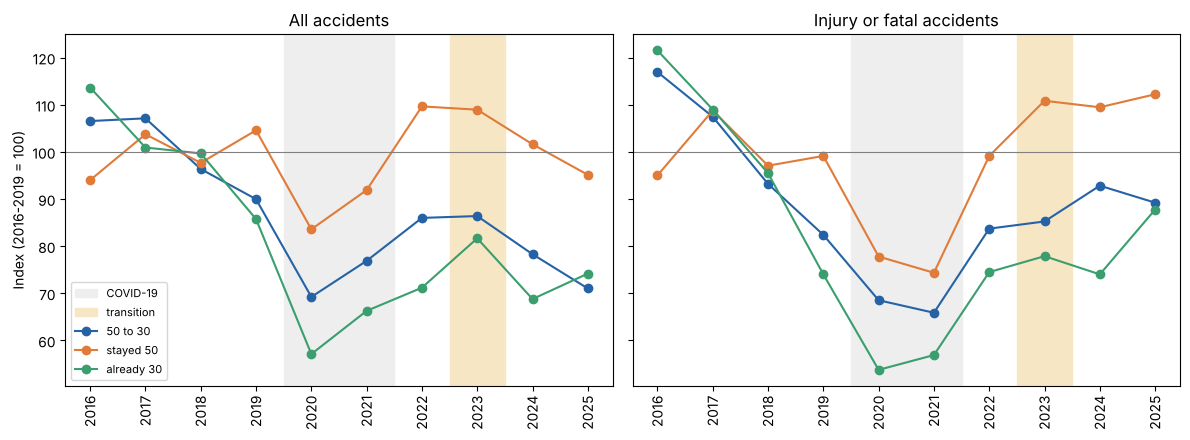

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, (col, title) in zip(axes, [("accidents", "All accidents"), ("serious", "Injury or fatal accidents")]):
    ax.axvspan(2019.5, 2021.5, color="#EEEEEE", label="COVID-19")
    ax.axvspan(2022.5, 2023.5, color="#F7E6C4", label="transition")
    for cat in groups:
        d = per_year[per_year["category"] == cat].set_index("year")[col]
        ax.plot(d.index, 100 * d / d.loc[2016:2019].mean(), marker="o", color=colors[cat], label=cat)
    ax.axhline(100, color="grey", linewidth=0.8)
    ax.set_title(title)
    ax.set_xticks(range(2016, 2026))
    ax.tick_params(axis="x", rotation=90)
axes[0].set_ylabel("Index (2016-2019 = 100)")
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.savefig("RQ1_index_per_category.png", dpi=200, bbox_inches="tight")
plt.show()

In [8]:
def prepare(control, source=per_year, drop_years=(2023,)):
    d = source[source["category"].isin(["50 to 30", control]) & ~source["year"].isin(drop_years)].copy()
    d["treated"] = (d["category"] == "50 to 30").astype(int)
    d["after"] = (d["year"] >= 2024).astype(int)
    d["t"] = d["year"] - 2016
    return d


def poisson(d, formula, term):
    m = smf.glm(formula, data=d, family=sm.families.Poisson()).fit(scale="X2")
    est = np.exp(m.params[term])
    low, high = np.exp(m.conf_int().loc[term])
    return est, low, high, m.pvalues[term]


print("Pre-trend test (before years without COVID): yearly ratio treated vs control")
for control in ["stayed 50", "already 30"]:
    for measure in ["accidents", "serious"]:
        pre = prepare(control)
        pre = pre[pre["year"].isin([2016, 2017, 2018, 2019, 2022])]
        est, low, high, p = poisson(pre, f"{measure} ~ treated * t", "treated:t")
        print(control, measure, round(est, 3), "CI:", round(low, 3), "-", round(high, 3), "p =", round(p, 3))

Pre-trend test (before years without COVID): yearly ratio treated vs control
stayed 50 accidents 0.94 CI: 0.914 - 0.967 p = 0.0
stayed 50 serious 0.943 CI: 0.887 - 1.003 p = 0.063
already 30 accidents 1.038 CI: 1.012 - 1.064 p = 0.003
already 30 serious 1.031 CI: 0.967 - 1.099 p = 0.35


In [9]:
did_formula = "{m} ~ C(category) + C(year) + treated:after"
trend_formula = "{m} ~ C(category) + C(year) + treated:t + treated:after"

rows = []
for control in ["stayed 50", "already 30"]:
    for measure in ["accidents", "serious", "fatal"]:
        d = prepare(control)
        for model, formula in [("DiD", did_formula), ("DiD + trend", trend_formula)]:
            if model == "DiD + trend" and measure == "fatal":
                continue
            est, low, high, p = poisson(d, formula.format(m=measure), "treated:after")
            rows.append({"control": control, "measure": measure, "model": model, "IRR": est,
                         "CI low": low, "CI high": high, "p": p, "change %": 100 * (est - 1)})

did_results = pd.DataFrame(rows).round(3)
did_results

,control,measure,model,IRR,CI low,CI high,p,change %
0,stayed 50,accidents,DiD,0.823,0.671,1.009,0.061,-17.745
1,stayed 50,accidents,DiD + trend,1.151,1.044,1.268,0.005,15.068
2,stayed 50,serious,DiD,0.865,0.713,1.050,0.143,-13.469
3,stayed 50,serious,DiD + trend,1.169,0.956,1.429,0.128,16.910
4,stayed 50,fatal,DiD,0.912,0.357,2.326,0.846,-8.838
5,already 30,accidents,DiD,0.982,0.824,1.171,0.843,-1.757
6,already 30,accidents,DiD + trend,0.789,0.642,0.969,0.024,-21.121
7,already 30,serious,DiD,1.065,0.897,1.265,0.470,6.532
8,already 30,serious,DiD + trend,0.877,0.686,1.120,0.293,-12.332
9,already 30,fatal,DiD,3.167,0.632,15.858,0.161,216.667


In [10]:
rows = []
for control in ["stayed 50", "already 30"]:
    d = data[data["category"].isin(["50 to 30", control]) & (data["period"] != "transition")].copy()
    d["treated"] = (d["category"] == "50 to 30").astype(int)
    d["after"] = (d["period"] == "after").astype(int)
    d["serious"] = d["serious"].astype(int)
    m = smf.logit("serious ~ C(category) + C(year) + treated:after", data=d).fit(disp=False)
    low, high = np.exp(m.conf_int().loc["treated:after"])
    rows.append({"control": control, "OR": np.exp(m.params["treated:after"]),
                 "CI low": low, "CI high": high, "p": m.pvalues["treated:after"]})

pd.DataFrame(rows).round(3)

,control,OR,CI low,CI high,p
0,stayed 50,1.105,0.935,1.306,0.242
1,already 30,1.134,0.995,1.292,0.060


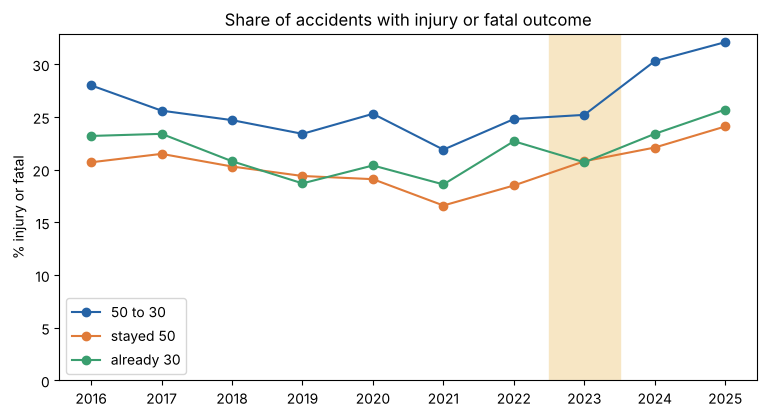

In [11]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.axvspan(2022.5, 2023.5, color="#F7E6C4")
for cat in groups:
    d = per_year[per_year["category"] == cat]
    ax.plot(d["year"], d["% serious"], marker="o", color=colors[cat], label=cat)
ax.set_ylim(0, None)
ax.set_xticks(range(2016, 2026))
ax.set_ylabel("% injury or fatal")
ax.set_title("Share of accidents with injury or fatal outcome")
ax.legend()
plt.savefig("RQ1_share_serious_per_category.png", dpi=200, bbox_inches="tight")
plt.show()

In [12]:
segments_only = count_per_year(data[data["location_type"] == "segment"])
checks = {
    "main analysis": prepare("stayed 50"),
    "without 2020-2021": prepare("stayed 50", drop_years=(2020, 2021, 2023)),
    "road segments only": prepare("stayed 50", source=segments_only),
    "before = 2022 only": prepare("stayed 50", drop_years=(2016, 2017, 2018, 2019, 2020, 2021, 2023)),
}

rows = []
for name, d in checks.items():
    for measure in ["accidents", "serious"]:
        est, low, high, p = poisson(d, did_formula.format(m=measure), "treated:after")
        rows.append({"analysis": name, "measure": measure, "IRR": est, "CI low": low, "CI high": high, "p": p})

pd.DataFrame(rows).round(3)

,analysis,measure,IRR,CI low,CI high,p
0,main analysis,accidents,0.823,0.671,1.009,0.061
1,main analysis,serious,0.865,0.713,1.050,0.143
2,without 2020-2021,accidents,0.796,0.636,0.995,0.045
3,without 2020-2021,serious,0.847,0.675,1.064,0.154
4,road segments only,accidents,0.774,0.621,0.966,0.023
5,road segments only,serious,0.892,0.694,1.147,0.373
6,before = 2022 only,accidents,0.968,0.919,1.019,0.210
7,before = 2022 only,serious,0.972,0.868,1.089,0.630


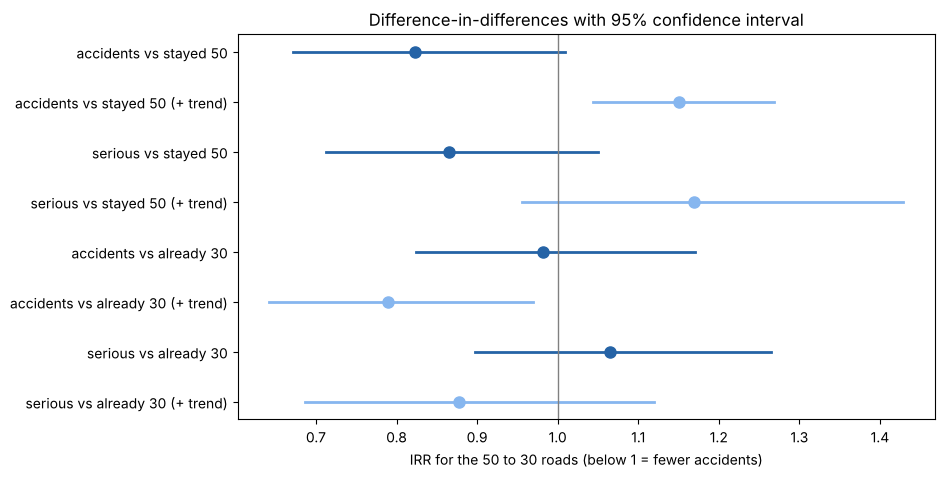

In [13]:
plot = did_results[did_results["measure"] != "fatal"]
labels = [f"{r.measure} vs {r.control}" + (" (+ trend)" if r.model == "DiD + trend" else "") for r in plot.itertuples()]

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(plot))[::-1]
for yi, (_, r) in zip(y, plot.iterrows()):
    color = "#86B6EF" if r["model"] == "DiD + trend" else "#2563A6"
    ax.plot([r["CI low"], r["CI high"]], [yi, yi], color=color, linewidth=2)
    ax.plot(r["IRR"], yi, "o", color=color, markersize=8)
ax.axvline(1, color="grey", linewidth=1)
ax.set_yticks(y)
ax.set_yticklabels(labels)
ax.set_xlabel("IRR for the 50 to 30 roads (below 1 = fewer accidents)")
ax.set_title("Difference-in-differences with 95% confidence interval")
plt.savefig("RQ1_did_results.png", dpi=200, bbox_inches="tight")
plt.show()

Compared with the roads that stayed 50, the 50 to 30 roads have about 18% fewer accidents (p = 0.06), but they were already dropping faster before 2023. Compared with the streets that were already 30 there is almost no difference (-2%). The pre-trends are not parallel for either control group, and when we correct for them the results go in opposite directions (+15% against the roads that stayed 50, -21% against the streets that were already 30). So the result depends on which roads we compare with, and we cannot say that the 30 km/h limit caused an extra drop on the changed roads. The number of serious accidents on the changed roads stayed about the same, so their share went up from 25% to 31% because mainly light accidents disappeared, but this rise is not significant compared with the control roads.